Эеконометрическое моделирование КЕЙС2
-------------------------------------------------
2й кейс - гетероскедастичность h-price тесты (+ анализ визуальной диагностики - гетероскедастичности)
-------------------------------------------------
МЕТОДЫ (перечислены ниже)
1. МНК-регресия, также МНК-регрессия метод НC-3 или HCCM корректировкой на расчёт стандартных ошибок модели для малых выборок
2. ВМНК (VLS) с изменёнными стандартными ошибками автоматически и руками (Python и excel)
3. ДВМНК (вес задаётся нормативно)
Попробовать на графике приложить модели с корректировкой, после каждой корректировки - диагностика,
(Можно добавить Бокса-Кокса)
сохраняем ряд остатков -> после поправок делать тест на гетероскедастичность
-------------------------------------------------
В основании решить интерпретацию лушего метода, описать итоги

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.stats.api as sms
import statsmodels.api as sm

## 1. МНК-регрессия метод НC-3 поправкой

In [15]:
df = pd.read_csv('urozhaynost_usl_own_variance.csv')

In [16]:
X = df.drop('Y', axis=1)
Y = df['Y']

In [17]:
#Через statmodels
model = sm.OLS(Y, sm.add_constant(X)).fit()
model_hc3 = model.get_robustcov_results(cov_type='HC3')

In [18]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.490
Model:                            OLS   Adj. R-squared:                  0.294
Method:                 Least Squares   F-statistic:                     2.499
Date:                Mon, 09 Nov 2026   Prob (F-statistic):             0.0852
Time:                        09:34:57   Log-Likelihood:                -33.461
No. Observations:                  19   AIC:                             78.92
Df Residuals:                      13   BIC:                             84.59
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0717      6.063      0.837      0.418      -8.026      18.170
X1            -0.1354      1.053     -0.129      0.900      -2.411       2.140
X2             9.0475     24.322      0.372      0.716     -43.498      61.593
X3             0.2732      0.959      0.285      0.780      -1.799       2.345
X4             3.9842      1.670      2.386      0.033       0.377       7.591
X5            -1.2958      3.349     -0.387      0.705      -8.531       5.940
==============================================================================
Omnibus:                        6.728   Durbin-Watson:                   2.583
Prob(Omnibus):                  0.035   Jarque-Bera (JB):                4.373
Skew:                           1.128   Prob(JB):                        0.112
Kurtosis:                       3.660   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [19]:
model_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.490
Model:                            OLS   Adj. R-squared:                  0.294
Method:                 Least Squares   F-statistic:                     2.314
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.104
Time:                        09:34:57   Log-Likelihood:                -33.461
No. Observations:                  19   AIC:                             78.92
Df Residuals:                      13   BIC:                             84.59
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          5.0717      5.215      0.972      0.349      -6.195      16.339
X1            -0.1354      1.508     -0.090      0.930      -3.393       3.122
X2             9.0475     21.544      0.420      0.681     -37.496      55.591
X3             0.2732      1.273      0.215      0.833      -2.478       3.024
X4             3.9842      2.224      1.791      0.097      -0.821       8.789
X5            -1.2958      3.258     -0.398      0.697      -8.335       5.743
==============================================================================
Omnibus:                        6.728   Durbin-Watson:                   2.583
Prob(Omnibus):                  0.035   Jarque-Bera (JB):                4.373
Skew:                           1.128   Prob(JB):                        0.112
Kurtosis:                       3.660   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [20]:
bp_test = sms.het_breuschpagan(model.resid, model.model.exog)

# Создаем красивую таблицу
bp_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test[0], 4), round(bp_test[1], 4), round(bp_test[2], 4), round(bp_test[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,3.4222
1,p-value,0.6352
2,F-статистика,0.5712
3,F p-value,0.7211


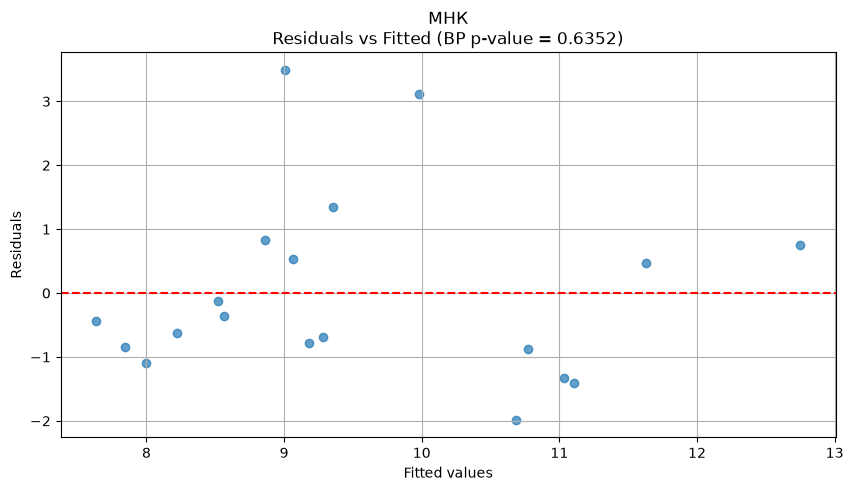

In [81]:
# Для ЛЮБОЙ модели (МНК, ВМНК, ДВМНК)
plt.figure(figsize=(10, 5))
plt.scatter(model.fittedvalues, model.resid, alpha=0.7)  # Ключевое: fittedvalues vs resid
plt.axhline(0, linestyle='--', color='red')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title(f'МНК\nResiduals vs Fitted (BP p-value = {bp_test[1]:.4f})')
plt.grid(True)
plt.savefig('residuals_МНК.png', dpi=300, bbox_inches='tight');

## 2. ВМНК (WLS) с изменёнными стандартными ошибками

In [22]:
model = ols(f"Y ~ {'+'.join(df.drop('Y', axis=1).columns)}", df).fit()

In [23]:
# --- ПОДГОТОВКА ДАННЫХ ---
X_raw = df.drop('Y', axis=1)
y_raw = df['Y']
X_mat = np.asarray(sm.add_constant(X_raw))  # Матрица (19, 6)
y_mat = np.asarray(y_raw).reshape(-1, 1)    # Вектор-столбец (19, 1)

In [24]:
# --- ШАГ 1: Считаем веса ---
# (Модель для логарифма остатков)
log_e = np.log((model.resid) ** 2) # или взять model.resid
Extended_model = sm.OLS(log_e, X_mat).fit()
variances = np.exp(Extended_model.predict(X_mat)) # (19,)
w = 1 / variances # (19,) - это наши веса!

In [25]:
# --- ШАГ 2: Ручной расчет B_wls (если не сделали) ---
W = np.diag(w)
B_wls = np.linalg.inv(X_mat.T @ W @ X_mat) @ (X_mat.T @ W @ y_mat)

In [26]:
# 1. Остатки от ВМНК (превращаем в одномерный массив)
y_pred_wls = X_mat @ B_wls
e_wls = (y_mat - y_pred_wls).ravel() # (19,)

In [27]:
# 2. Корень из весов
sqrt_w = np.sqrt(w).ravel() # (19,)

In [28]:
# 3. Взвешенная матрица X* и взвешенные остатки e*
# В NumPy лучше умножать каждую СТРОКУ X_mat на sqrt_w. 
# Для этого можно умножить X_mat на sqrt_w[:, None] (добавит измерение столбца)
X_star = X_mat * sqrt_w[:, None] 
e_star = e_wls * sqrt_w

In [29]:
# 4. Рычаги h_ii для взвешенной модели
XtX_star_inv = np.linalg.inv(X_star.T @ X_star)
H_star = X_star @ XtX_star_inv @ X_star.T
h_star = H_star.diagonal()

In [30]:
# 5. Веса для HC3
omega = (e_star ** 2) / ((1 - h_star) ** 2)
Omega = np.diag(omega)

In [31]:
# 6. Собираем "сэндвич" для ВМНК
cov_wls_hc3 = XtX_star_inv @ (X_star.T @ Omega @ X_star) @ XtX_star_inv

In [32]:
# 7. Извлекаем стандартные ошибки
se_wls_hc3 = np.sqrt(np.diag(cov_wls_hc3))
print("Стандартные ошибки ВМНК (HC3):")
print(se_wls_hc3)

Стандартные ошибки ВМНК (HC3):
[ 3.45645284  1.20157439 13.62353713  0.98010781  1.87550245  2.41889746]


---------------------------------------------------------------------------

In [33]:
model_wls = sm.WLS(Y, sm.add_constant(X), weights=w).fit()
model_wls.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.796
Model:                            WLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     10.12
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           0.000400
Time:                        09:34:58   Log-Likelihood:                -28.840
No. Observations:                  19   AIC:                             69.68
Df Residuals:                      13   BIC:                             75.35
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.8470      3.951      1.227      0.242      -3.688      13.382
X1            -0.4574      1.056     -0.433      0.672      -2.738       1.823
X2             8.8068     16.336      0.539      0.599     -26.485      44.099
X3             0.6093      0.889      0.685      0.505      -1.311       2.530
X4             5.1771      1.767      2.930      0.012       1.360       8.994
X5            -2.6311      2.732     -0.963      0.353      -8.533       3.271
==============================================================================
Omnibus:                        4.885   Durbin-Watson:                   2.574
Prob(Omnibus):                  0.087   Jarque-Bera (JB):                2.920
Skew:                           0.932   Prob(JB):                        0.232
Kurtosis:                       3.459   Cond. No.                         520.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [34]:
model_wls_hc3 = model_wls.get_robustcov_results(cov_type='HC3')
model_wls_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.796
Model:                            WLS   Adj. R-squared:                  0.717
Method:                 Least Squares   F-statistic:                     7.758
Date:                Mon, 09 Nov 2026   Prob (F-statistic):            0.00141
Time:                        09:34:58   Log-Likelihood:                -28.840
No. Observations:                  19   AIC:                             69.68
Df Residuals:                      13   BIC:                             75.35
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.8470      3.456      1.402      0.184      -2.620      12.314
X1            -0.4574      1.202     -0.381      0.710      -3.053       2.138
X2             8.8068     13.624      0.646      0.529     -20.625      38.239
X3             0.6093      0.980      0.622      0.545      -1.508       2.727
X4             5.1771      1.876      2.760      0.016       1.125       9.229
X5            -2.6311      2.419     -1.088      0.296      -7.857       2.595
==============================================================================
Omnibus:                        4.885   Durbin-Watson:                   2.574
Prob(Omnibus):                  0.087   Jarque-Bera (JB):                2.920
Skew:                           0.932   Prob(JB):                        0.232
Kurtosis:                       3.459   Cond. No.                         520.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [35]:
bp_test_wls = sms.het_breuschpagan(model_wls.resid, model_wls.model.exog)

# Создаем красивую таблицу
bp_wls_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test_wls[0], 4), round(bp_test_wls[1], 4), round(bp_test_wls[2], 4), round(bp_test_wls[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_wls_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,4.6911
1,p-value,0.4547
2,F-статистика,0.8524
3,F p-value,0.5373


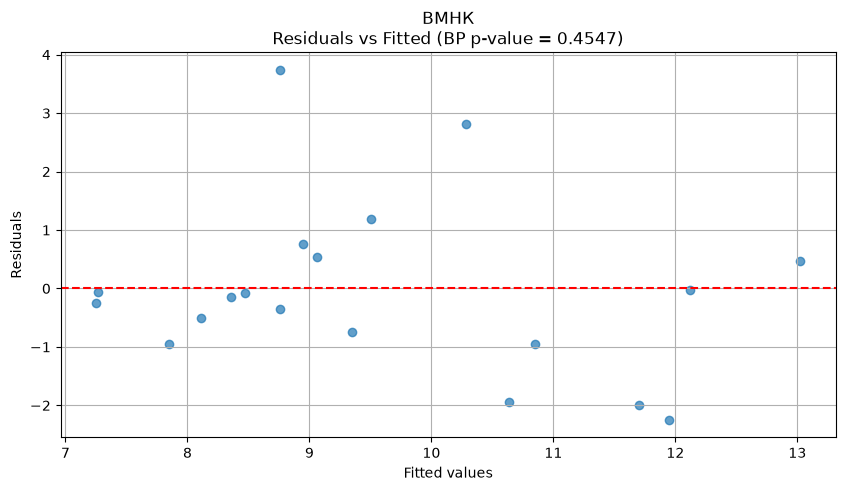

In [83]:
# Для ЛЮБОЙ модели (МНК, ВМНК, ДВМНК)
plt.figure(figsize=(10, 5))
plt.scatter(model_wls.fittedvalues, model_wls.resid, alpha=0.7)  # Ключевое: fittedvalues vs resid
plt.axhline(0, linestyle='--', color='red')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title(f'ВМНК\nResiduals vs Fitted (BP p-value = {bp_test_wls[1]:.4f})')
plt.grid(True)
plt.savefig('residuals_ВМНК.png', dpi=300, bbox_inches='tight');

## 3. ДВМНК (вес задаётся нормативно)

In [62]:
X = df.drop('Y', axis=1)
y = df['Y']
weights = 1 / df['X4']

In [63]:
model_TSLS = sm.WLS(y, sm.add_constant(X), weights=weights).fit()

In [64]:
model_TSLS.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.623
Model:                            WLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     4.289
Date:                Mon, 09 Nov 2026   Prob (F-statistic):             0.0159
Time:                        10:26:11   Log-Likelihood:                -31.121
No. Observations:                  19   AIC:                             74.24
Df Residuals:                      13   BIC:                             79.91
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.6766      5.021      0.732      0.477      -7.171      14.524
X1            -0.2498      1.104     -0.226      0.825      -2.636       2.136
X2            13.2333     19.972      0.663      0.519     -29.913      56.380
X3             0.3586      0.948      0.378      0.711      -1.690       2.408
X4             5.0860      1.680      3.028      0.010       1.457       8.715
X5            -2.4088      2.984     -0.807      0.434      -8.855       4.037
==============================================================================
Omnibus:                        7.589   Durbin-Watson:                   2.533
Prob(Omnibus):                  0.022   Jarque-Bera (JB):                4.999
Skew:                           1.177   Prob(JB):                       0.0821
Kurtosis:                       3.877   Cond. No.                         264.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [65]:
model_TSLS_hc3 = model_TSLS.get_robustcov_results(cov_type='HC3')
model_TSLS_hc3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            WLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.623
Model:                            WLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     4.823
Date:                Mon, 09 Nov 2026   Prob (F-statistic):             0.0103
Time:                        10:26:13   Log-Likelihood:                -31.121
No. Observations:                  19   AIC:                             74.24
Df Residuals:                      13   BIC:                             79.91
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          3.6766      4.435      0.829      0.422      -5.905      13.258
X1            -0.2498      1.206     -0.207      0.839      -2.854       2.355
X2            13.2333     17.694      0.748      0.468     -24.992      51.459
X3             0.3586      0.959      0.374      0.714      -1.713       2.430
X4             5.0860      1.947      2.612      0.022       0.879       9.293
X5            -2.4088      2.544     -0.947      0.361      -7.906       3.088
==============================================================================
Omnibus:                        7.589   Durbin-Watson:                   2.533
Prob(Omnibus):                  0.022   Jarque-Bera (JB):                4.999
Skew:                           1.177   Prob(JB):                       0.0821
Kurtosis:                       3.877   Cond. No.                         264.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [66]:
bp_test_tsls = sms.het_breuschpagan(model_TSLS.resid, model_TSLS.model.exog)

# Создаем красивую таблицу
bp_tsls_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test_tsls[0], 4), round(bp_test_tsls[1], 4), round(bp_test_tsls[2], 4), round(bp_test_tsls[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_tsls_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,4.2429
1,p-value,0.5150
2,F-статистика,0.7476
3,F p-value,0.6021


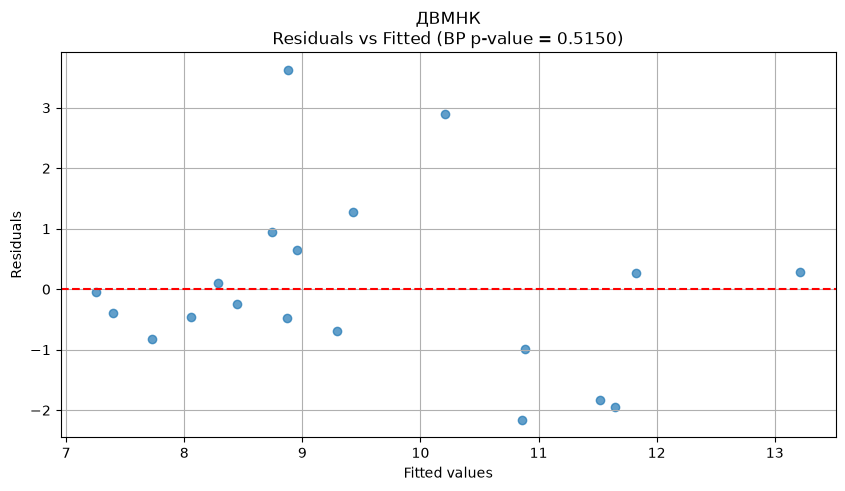

In [85]:
# Для ЛЮБОЙ модели (МНК, ВМНК, ДВМНК)
plt.figure(figsize=(10, 5))
plt.scatter(model_TSLS.fittedvalues, model_TSLS.resid, alpha=0.7)  # Ключевое: fittedvalues vs resid
plt.axhline(0, linestyle='--', color='red')
plt.xlabel('Fitted values')
plt.ylabel('Residuals')
plt.title(f'ДВМНК\nResiduals vs Fitted (BP p-value = {bp_test_tsls[1]:.4f})')
plt.grid(True)
plt.savefig('residuals_ДВМНК.png', dpi=300, bbox_inches='tight');

X1
X2
X3
X4
X5


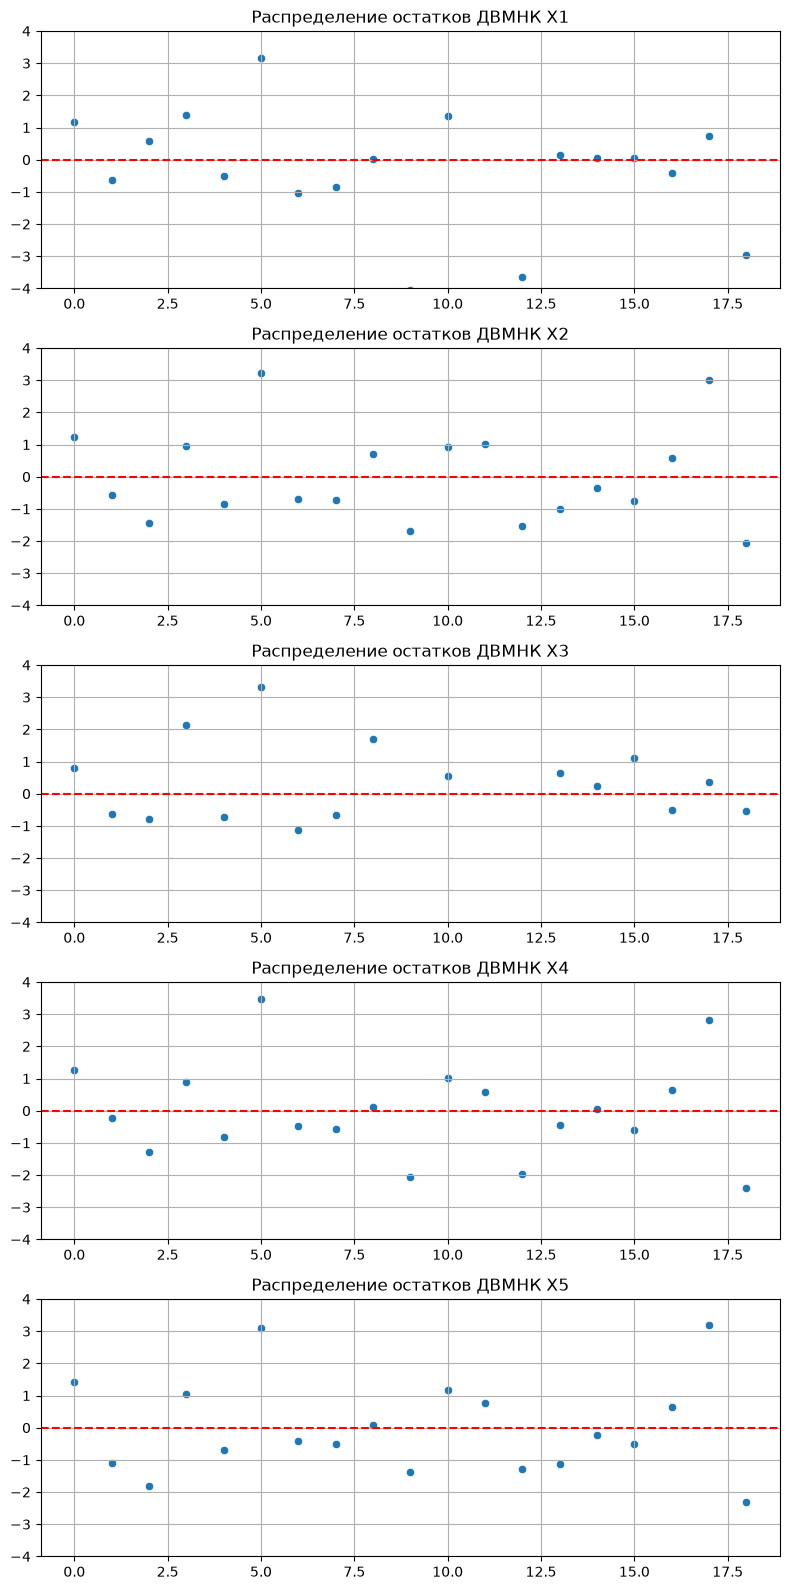

In [59]:
plt.figure(figsize=(8,16))
for i, col in enumerate(X.columns):
    print(col)
    w = 1 / df[col]
    md = sm.WLS(y, X, weights=w).fit()
    plt.subplot(5, 1, i+1)
    sns.scatterplot(md.resid)
    plt.ylim((-4, 4))
    plt.axhline(0, linestyle='--', color='red')
    plt.grid(True)
    plt.title(f'Распределение остатков ДВМНК {col}')
plt.tight_layout()

In [60]:
results_comparison = []

for col in X.columns:
    w = 1 / df[col]
    md = sm.WLS(y, sm.add_constant(X), weights=w).fit(cov_type='HC3')
    bp = sms.het_breuschpagan(md.resid, md.model.exog)
    
    results_comparison.append({
        'Вес по переменной': col,
        'R-squared': round(md.rsquared, 4),
        'AIC': round(md.aic, 2),
        'BIC': round(md.bic, 2),
        'BP p-value': round(bp[1], 4),
        'X4 coef': round(md.params['X4'], 4),
        'X4 p-value': round(md.pvalues['X4'], 4)
    })

df_comparison = pd.DataFrame(results_comparison)
print(df_comparison.to_string(index=False))

Вес по переменной  R-squared   AIC   BIC  BP p-value  X4 coef  X4 p-value
               X1     0.7811 85.91 91.57      0.0286   9.2525      0.1032
               X2     0.4782 79.49 85.16      0.6242   4.1281      0.0853
               X3     0.8837 84.35 90.02      0.0256   9.9622      0.1221
               X4     0.6226 74.24 79.91      0.5150   5.0860      0.0090
               X5     0.5121 77.51 83.18      0.6223   3.9223      0.0967


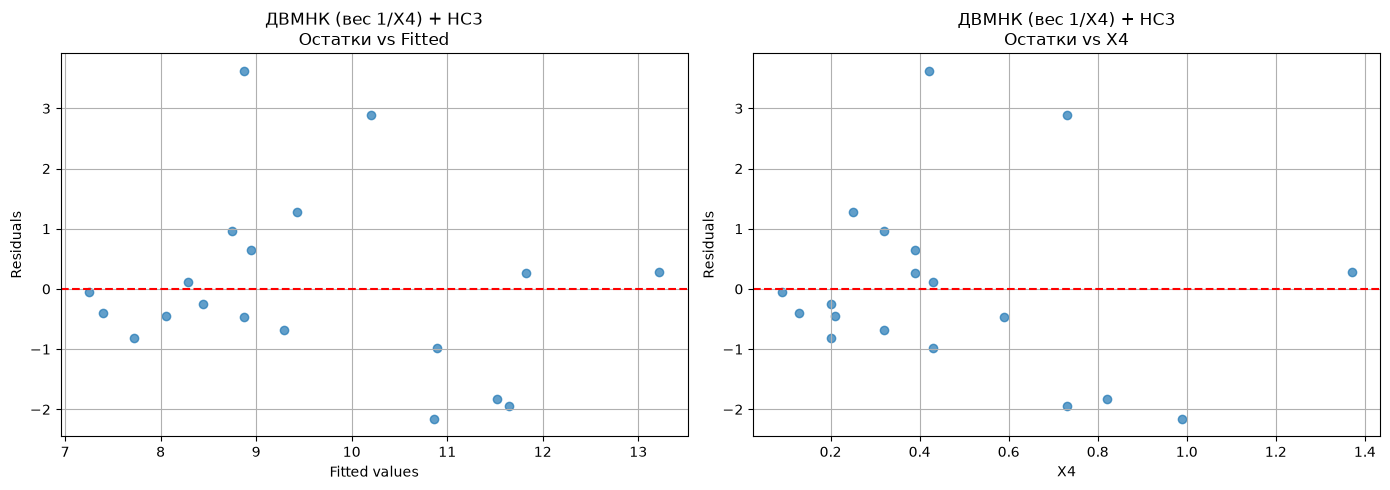

BP p-value финальной модели: 0.5150


In [61]:
# Финальная модель ДВМНК с лучшим весом
w_best = 1 / df['X4']
model_final = sm.WLS(y, sm.add_constant(X), weights=w_best).fit(cov_type='HC3')

# График 1: Остатки vs Fitted values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(model_final.fittedvalues, model_final.resid, alpha=0.7)
axes[0].axhline(0, linestyle='--', color='red')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('ДВМНК (вес 1/X4) + HC3\nОстатки vs Fitted')
axes[0].grid(True)

# График 2: Остатки vs X4 (переменная-вес)
axes[1].scatter(df['X4'], model_final.resid, alpha=0.7)
axes[1].axhline(0, linestyle='--', color='red')
axes[1].set_xlabel('X4')
axes[1].set_ylabel('Residuals')
axes[1].set_title('ДВМНК (вес 1/X4) + HC3\nОстатки vs X4')
axes[1].grid(True)

plt.tight_layout()
plt.show()

print(f"BP p-value финальной модели: {sms.het_breuschpagan(model_final.resid, model_final.model.exog)[1]:.4f}")

## Преобразование Бокса-Кокса

In [74]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.stats.diagnostic as sms
from scipy import stats
import matplotlib.pyplot as plt

# Предположим, ваши данные уже загружены в df, а X и y определены
# X = sm.add_constant(df[['X1', 'X2', 'X3', 'X4', 'X5']])
# y = df['Y']

# 1. Находим оптимальную лямбду для Y
y_transformed, lambda_val = stats.boxcox(y)
print(f"Оптимальное значение лямбда (λ): {lambda_val:.4f}")

# 2. Строим модель МНК для трансформированной Y
# Добавляем поправку HC-3 для малой выборки, как в предыдущих пунктах
model_boxcox = sm.OLS(y_transformed, sm.add_constant(X)).fit(cov_type='HC3')

print("\n--- Результаты модели Бокса-Кокса + HC-3 ---")
print(model_boxcox.summary().tables[1])

# 3. Тест Бройша-Пагана на остатках трансформированной модели
bp_bc = sms.het_breuschpagan(model_boxcox.resid, model_boxcox.model.exog)
print(f"\nТест Бройша-Пагана (Бокса-Кокса):")
print(f"LM Statistic: {bp_bc[0]:.4f}")
print(f"p-value: {bp_bc[1]:.4f}")

Оптимальное значение лямбда (λ): -0.7786

--- Результаты модели Бокса-Кокса + HC-3 ---
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9737      0.081     12.014      0.000       0.815       1.133
X1            -0.0064      0.022     -0.287      0.774      -0.050       0.038
X2             0.1714      0.329      0.521      0.602      -0.473       0.816
X3             0.0084      0.019      0.442      0.658      -0.029       0.046
X4             0.0757      0.035      2.154      0.031       0.007       0.145
X5            -0.0320      0.045     -0.706      0.480      -0.121       0.057

Тест Бройша-Пагана (Бокса-Кокса):
LM Statistic: 2.6145
p-value: 0.7592


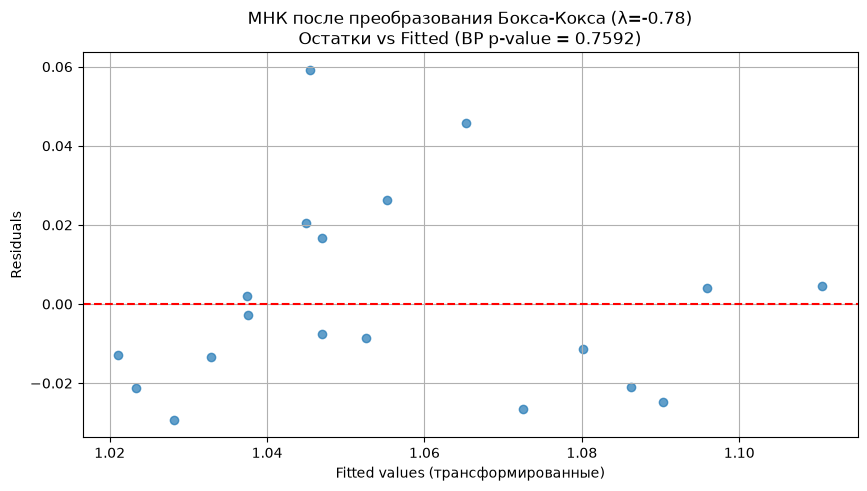

In [79]:
plt.figure(figsize=(10, 5))
plt.scatter(model_boxcox.fittedvalues, model_boxcox.resid, alpha=0.7)
plt.axhline(0, linestyle='--', color='red')
plt.xlabel('Fitted values (трансформированные)')
plt.ylabel('Residuals')
plt.title(f'МНК после преобразования Бокса-Кокса (λ={lambda_val:.2f})\nОстатки vs Fitted (BP p-value = {bp_bc[1]:.4f})')
plt.grid(True)
plt.savefig('Box_cox_transformation_residiuals.png', dpi=300, bbox_inches='tight');

In [70]:
model_boxcox.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.534
Model:                            OLS   Adj. R-squared:                  0.355
Method:                 Least Squares   F-statistic:                     4.477
Date:                Mon, 09 Nov 2026   Prob (F-statistic):             0.0136
Time:                        10:44:33   Log-Likelihood:                 44.113
No. Observations:                  19   AIC:                            -76.23
Df Residuals:                      13   BIC:                            -70.56
Df Model:                           5                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.9737      0.081     12.014      0.000       0.815       1.133
X1            -0.0064      0.022     -0.287      0.774      -0.050       0.038
X2             0.1714      0.329      0.521      0.602      -0.473       0.816
X3             0.0084      0.019      0.442      0.658      -0.029       0.046
X4             0.0757      0.035      2.154      0.031       0.007       0.145
X5            -0.0320      0.045     -0.706      0.480      -0.121       0.057
==============================================================================
Omnibus:                        4.810   Durbin-Watson:                   2.376
Prob(Omnibus):                  0.090   Jarque-Bera (JB):                3.115
Skew:                           0.985   Prob(JB):                        0.211
Kurtosis:                       3.232   Cond. No.                         292.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [72]:
bp_test_box_cox = sms.het_breuschpagan(model_boxcox.resid, model_boxcox.model.exog)

# Создаем красивую таблицу
bp_box_cox_table = pd.DataFrame({
    'Показатель': ['Статистика LM', 'p-value', 'F-статистика', 'F p-value'],
    'Значение': [round(bp_test_box_cox[0], 4), round(bp_test_box_cox[1], 4), round(bp_test_box_cox[2], 4), round(bp_test_box_cox[3], 4)]
})

print("Результаты теста Бройша-Пагана:")
display(bp_box_cox_table)

Результаты теста Бройша-Пагана:


,Показатель,Значение
0,Статистика LM,2.6145
1,p-value,0.7592
2,F-статистика,0.4149
3,F p-value,0.8302


## Вывод

Оптимальной спецификацией признана ДВМНК с нормативным весом 1/X4. Она обеспечивает лучший баланс: успешно нивелирует гетероскедастичность (BP p = 0.515), гарантирует высокую значимость ключевого фактора X4 (p = 0.022) и сохраняет прозрачную экономическую интерпретацию результатов.